# Домашнее задание 9.3 — Почему массу нельзя всегда диагонализовать? (🟢)

Рассматриваю локальный треугольник $T=\{x\ge0,\ y\ge0,\ x+y\le1\}$ с единичной плотностью и площадью $1/2$. Интегралы полиномов вычисляю точно; численные спектральные проверки провожу с абсолютным допуском $10^{-10}$. Порядок узлов: вершины 1, 2, 3; середины рёбер 12, 23, 31.

**Зелёный уровень.** Проверяю линейный и стандартный квадратичный элементы, их согласованные матрицы масс и результат построчной диагонализации.

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from IPython.display import display

TOL = 1e-10
x, y = sp.symbols("x y", real=True)
lam = [1-x-y, x, y]
nodes1 = [(0, 0), (1, 0), (0, 1)]
nodes2 = nodes1 + [(sp.Rational(1,2), 0), (sp.Rational(1,2), sp.Rational(1,2)), (0, sp.Rational(1,2))]
nodes7 = nodes2 + [(sp.Rational(1,3), sp.Rational(1,3))]
labels = ['1', '2', '3', '12', '23', '31', 'c']
P1 = lam
P2 = [l*(2*l-1) for l in lam] + [4*lam[0]*lam[1], 4*lam[1]*lam[2], 4*lam[2]*lam[0]]
def integ(f):
    return sp.integrate(sp.integrate(sp.expand(f), (y, 0, 1-x)), (x, 0, 1))
def at(f, p):
    return sp.expand(f).subs({x:p[0], y:p[1]})
def gram(fs):
    return sp.Matrix([[integ(a*b) for b in fs] for a in fs])
def as_float(A):
    return np.array(A, dtype=float)
def show_matrix(name, A):
    print(name)
    display(A)


## 1. Узлы и функции стандартных элементов

Вершинная функция $P_2$ отрицательна в части треугольника; общая цветовая шкала позволяет сравнить её с рёберной.

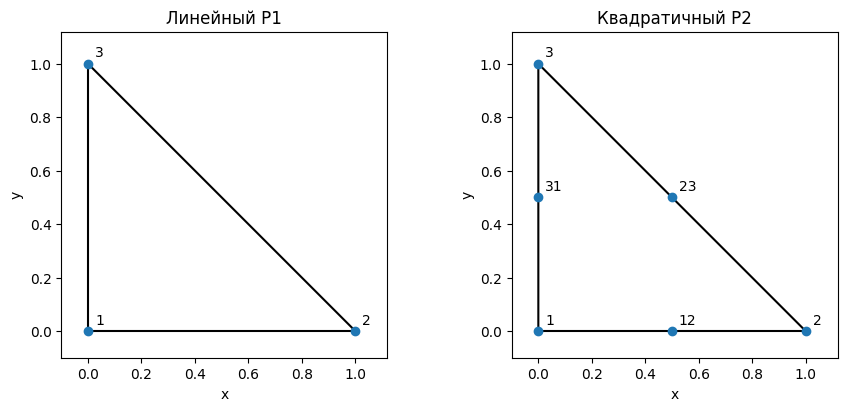

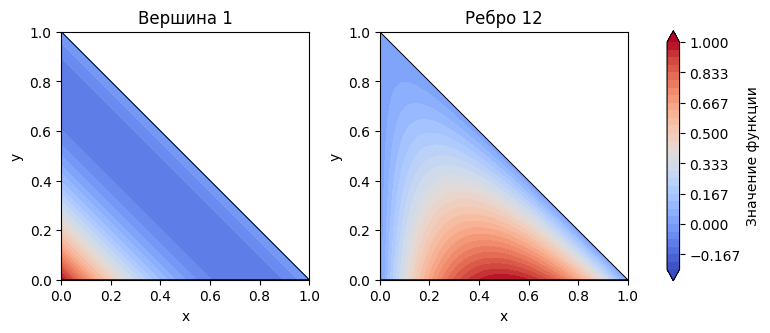

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, points, title in zip(axes, [nodes1, nodes2], ['Линейный P1', 'Квадратичный P2']):
    ax.plot([0, 1, 0, 0], [0, 0, 1, 0], color='black')
    for i, (xx, yy) in enumerate(points):
        ax.scatter(float(xx), float(yy), color='tab:blue', zorder=3)
        ax.annotate(labels[i], (float(xx), float(yy)), xytext=(5, 5), textcoords='offset points')
    ax.set(title=title, xlabel='x', ylabel='y', xlim=(-.1,1.12), ylim=(-.1,1.12), aspect='equal')
plt.show()

grid = np.linspace(0, 1, 101)
xy = np.array([(a, b) for a in grid for b in grid if a+b <= 1+1e-12])
tri = mtri.Triangulation(xy[:,0], xy[:,1])
def values(f):
    return np.asarray(sp.lambdify((x,y), f, 'numpy')(xy[:,0],xy[:,1]))
def maps(fs, names, ncols, limits):
    rows = (len(fs)+ncols-1)//ncols
    fig, axes = plt.subplots(rows, ncols, figsize=(3.8*ncols, 3.4*rows), squeeze=False, constrained_layout=True)
    for ax, f, name in zip(axes.flat, fs, names):
        im = ax.tricontourf(tri, values(f), levels=np.linspace(*limits, 31), cmap='coolwarm', extend='both')
        ax.plot([0,1,0,0], [0,0,1,0], 'k-', lw=.7)
        ax.set(title=name, xlabel='x', ylabel='y', aspect='equal')
    for ax in list(axes.flat)[len(fs):]: ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat), label='Значение функции', shrink=.8)
    plt.show()
maps([P2[0], P2[3]], ['Вершина 1', 'Ребро 12'], 2, (-.25, 1))

## 2. Согласованная и диагональная массы

$M_{ij}=\int_T\varphi_i\varphi_j\,dx\,dy$, $m=M\mathbf1$ и $M_L=\mathrm{diag}(m)$. Нодальность и разбиение единицы проверяются точно; для спектров использую симметричный алгоритм `eigvalsh`.

In [3]:
for name, fs, pts in [('P1', P1, nodes1), ('P2', P2, nodes2)]:
    M = gram(fs)
    masses = M * sp.ones(len(fs), 1)
    nodal = sp.Matrix([[at(f,p) for f in fs] for p in pts])
    eig = np.linalg.eigvalsh(as_float(M))
    diag_eig = np.linalg.eigvalsh(np.diag(np.asarray(masses, dtype=float).ravel()))
    assert nodal == sp.eye(len(fs))
    assert sp.expand(sum(fs)-1) == 0
    assert M == M.T and eig.min() > TOL
    assert sum(masses) == sp.Rational(1,2)
    show_matrix(name + ': M', M)
    show_matrix(name + ': m = M·1', masses)
    print('Нодальность, разбиение единицы, симметрия, SPD и масса 1/2: выполнены')
    print('eig(M)   =', np.round(eig, 10))
    print('eig(M_L) =', np.round(diag_eig, 10), '\n')

P1: M


Matrix([
[1/12, 1/24, 1/24],
[1/24, 1/12, 1/24],
[1/24, 1/24, 1/12]])

P1: m = M·1


Matrix([
[1/6],
[1/6],
[1/6]])

Нодальность, разбиение единицы, симметрия, SPD и масса 1/2: выполнены
eig(M)   = [0.04166667 0.04166667 0.16666667]
eig(M_L) = [0.16666667 0.16666667 0.16666667] 

P2: M


Matrix([
[  1/60, -1/360, -1/360,     0, -1/90,     0],
[-1/360,   1/60, -1/360,     0,     0, -1/90],
[-1/360, -1/360,   1/60, -1/90,     0,     0],
[     0,      0,  -1/90,  4/45,  2/45,  2/45],
[ -1/90,      0,      0,  2/45,  4/45,  2/45],
[     0,  -1/90,      0,  2/45,  2/45,  4/45]])

P2: m = M·1


Matrix([
[  0],
[  0],
[  0],
[1/6],
[1/6],
[1/6]])

Нодальность, разбиение единицы, симметрия, SPD и масса 1/2: выполнены
eig(M)   = [0.01037363 0.01522001 0.01522001 0.04866888 0.04866888 0.17851526]
eig(M_L) = [0.         0.         0.         0.16666667 0.16666667 0.16666667] 



У элемента $P_2$ три вершинные построчные массы равны нулю. Согласованная матрица положительно определена, но её построчные суммы — интегралы отдельных знакопеременных функций, а не собственные значения. Поэтому $M_L$ вырождена и деление на вершинную массу при вычислении ускорений невозможно.